# التجارب الأصلية / Original experiments

هذا الدفتر يحتفظ بجميع التجارب الأصلية وترتيب خلاياها. شغّله من البداية باستخدام نواة المشروع `.venv`.
أُضيفت معالجة للخطأ المتوقع في `solve` وتحذير LU عند المصفوفة المنفردة كي يستمر التشغيل؛ لا يعني فشل الطريقتين عدم وجود حلول.
عند فشل LU تكون `x_2_sc = None` بدل اعتبار أعداد غير صالحة حلًا.
للشرح المنظّم والفحوص الرياضية، راجع `../notebooks/Ax_equals_b_organized.ipynb`.


In [1]:
import numpy as np

In [2]:
np.__version__

'2.5.4'

In [3]:
A = np.array([[1, 2, 1], [2, 5, 3], [1, 3, 3]])

In [4]:
A

array([[1, 2, 1],
       [2, 5, 3],
       [1, 3, 3]])

In [5]:
b = np.array([4, 10, 7])

In [6]:
b

array([ 4, 10,  7])

In [7]:
x = np.linalg.solve(A, b)

In [8]:
print(A @ x)

[ 4. 10.  7.]


In [9]:
print(b)

[ 4 10  7]


In [10]:
A_2 = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]])
b_2 = np.array([6, 12, 3])

try:
    x_2 = np.linalg.solve(A_2, b_2)
except np.linalg.LinAlgError as exc:
    print("Expected solve failure for a singular matrix:", exc)

Expected solve failure for a singular matrix: Singular matrix


In [11]:
print("Rank(A): ", np.linalg.matrix_rank(A_2))

Rank(A):  2


In [12]:
print("Rank(Augmented): ", np.linalg.matrix_rank(np.column_stack((A_2, b_2))))

Rank(Augmented):  2


In [13]:
print("Determinant:", np.linalg.det(A_2))

Determinant: 0.0


In [14]:
import scipy.linalg as sc

In [15]:
import warnings

x_2_sc = None
try:
    with warnings.catch_warnings():
        warnings.simplefilter("error", sc.LinAlgWarning)
        x_2_sc = sc.lu_solve(sc.lu_factor(A_2), b_2)
except (sc.LinAlgWarning, np.linalg.LinAlgError) as exc:
    print("Expected LU failure for a singular matrix:", exc)
    print("Use the symbolic solution in the following cells.")


Expected LU failure for a singular matrix: Diagonal number 3 is exactly zero. Singular matrix.
Use the symbolic solution in the following cells.


In [16]:
x_2_sc

In [17]:
import sympy as sp

A_sym = sp.Matrix(A_2)
b_sym = sp.Matrix(b_2)

solution, parameters = A_sym.gauss_jordan_solve(b_sym)

display(solution)
display(parameters)

Matrix([
[      tau0],
[3 - 2*tau0],
[      tau0]])

Matrix([[tau0]])

In [18]:
S = np.array([0, 3, 0])

In [19]:
print(A_2 @ S)
print(b_2)

[ 6 12  3]
[ 6 12  3]


In [20]:
print(A_2 @ np.array([1, -2, 1]))

[0 0 0]


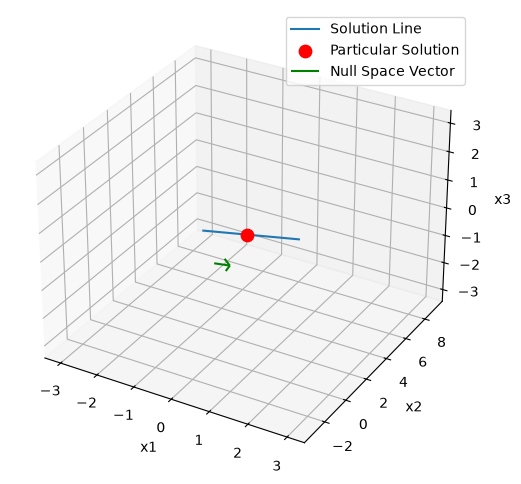

In [21]:
import numpy as np
import matplotlib.pyplot as plt

xp = np.array([0, 3, 0])
v = np.array([1, -2, 1])

t = np.linspace(-3, 3, 100)

# All solutions of Ax = b
solutions = xp + t[:, None] * v

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

# Draw the solution line
ax.plot(solutions[:, 0], solutions[:, 1], solutions[:, 2], label="Solution Line")

# Draw the particular solution
ax.scatter(*xp, color="red", s=80, label="Particular Solution")

# Draw the null space direction
ax.quiver(0, 0, 0, *v, color="green", label="Null Space Vector")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")

ax.legend()
plt.show()

In [22]:
A_3 = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]])

In [23]:
A_3_Sym = sp.Matrix(A_3)

In [24]:
print(A_3_Sym.columnspace())

[Matrix([
[1],
[2],
[1]]), Matrix([
[2],
[4],
[1]])]


In [25]:
print(A_3_Sym.rowspace())

[Matrix([[1, 2, 3]]), Matrix([[0, -1, -2]])]


In [26]:
print(A_3_Sym.nullspace())

[Matrix([
[ 1],
[-2],
[ 1]])]


In [27]:
print(A_3_Sym.T.nullspace())

[Matrix([
[-2],
[ 1],
[ 0]])]


In [28]:
print("Column Space Dimension:", len(A_3_Sym.columnspace()))
print("Row Space Dimension:", len(A_3_Sym.rowspace()))
print("Null Space Dimension:", len(A_3_Sym.nullspace()))
print("Left Null Space Dimension:", len(A_3_Sym.T.nullspace()))

Column Space Dimension: 2
Row Space Dimension: 2
Null Space Dimension: 1
Left Null Space Dimension: 1


In [29]:
A_3_Sym.columnspace()[0] @ ((A_3_Sym.T.nullspace())[0].T)

Matrix([
[-2, 1, 0],
[-4, 2, 0],
[-2, 1, 0]])

In [30]:
u = A_3_Sym.columnspace()[0]
v = A_3_Sym.T.nullspace()[0]

print(u.dot(v))

0


In [31]:
u = A_3_Sym.rowspace()[0]
v = A_3_Sym.nullspace()[0]

print(u.dot(v))

0


Normal Vector: [-2  1  0]
Dot Product: 0


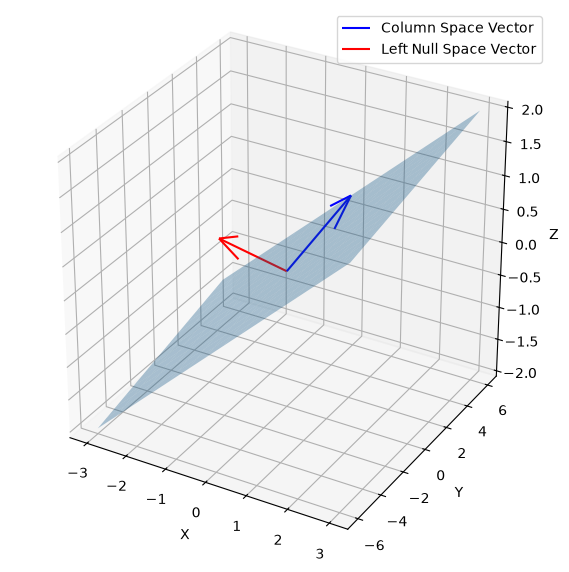

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Basis vectors of the Column Space
u = np.array([1, 2, 1])
v = np.array([2, 4, 1])

# Normal vector to the plane
n = np.cross(u, v)

print("Normal Vector:", n)
print("Dot Product:", np.dot(u, n))

# Generate the plane
s, t = np.meshgrid(np.linspace(-1, 1, 15), np.linspace(-1, 1, 15))

plane = s[..., None] * u + t[..., None] * v

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

# Column Space
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2], alpha=0.35)

# Vector in Column Space
ax.quiver(0, 0, 0, *u, color="blue", label="Column Space Vector")

# Vector in Left Null Space
ax.quiver(0, 0, 0, *n, color="red", label="Left Null Space Vector")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_box_aspect([1, 1, 1])
ax.legend()

plt.show()

Determinant: 6.0
Area Scale Factor: 6.0


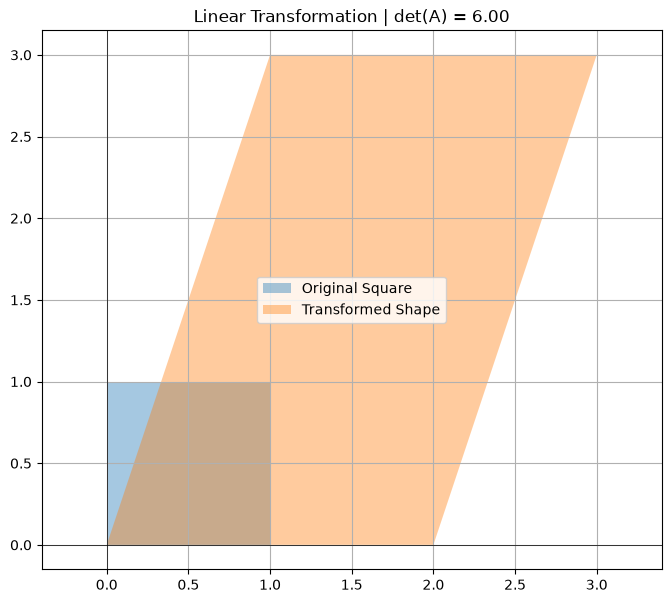

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A = np.array([[2, 1], [0, 3]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A.T

# Calculate Determinant
det = np.linalg.det(A)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

Determinant: 0.0
Area Scale Factor: 0.0


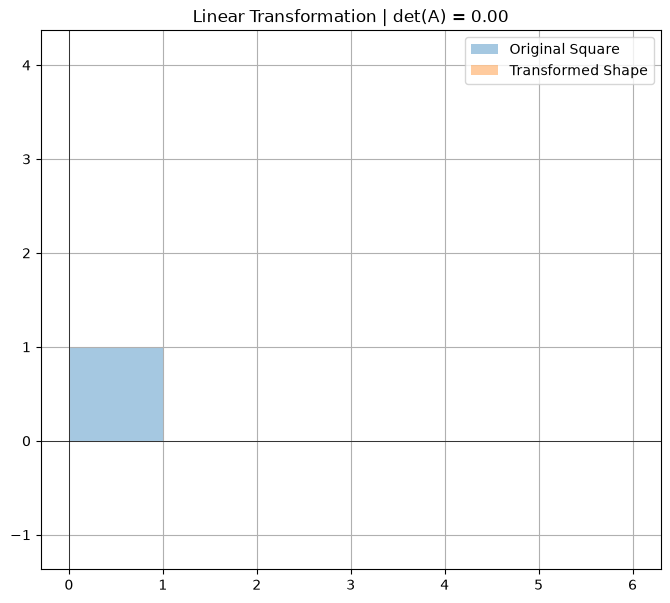

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A = np.array([[2, 4], [1, 2]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A.T

# Calculate Determinant
det = np.linalg.det(A)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

Determinant: -6.0
Area Scale Factor: 6.0


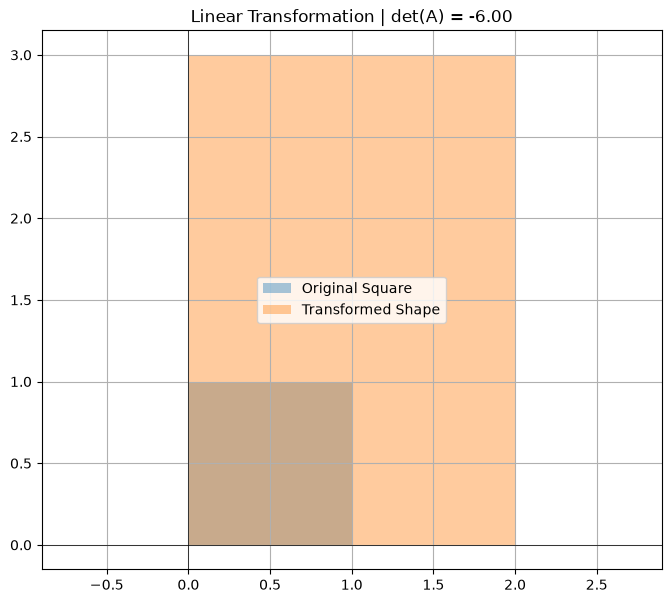

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A = np.array([[0, 2], [3, 0]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A.T

# Calculate Determinant
det = np.linalg.det(A)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

Determinant: 1.0
Area Scale Factor: 1.0


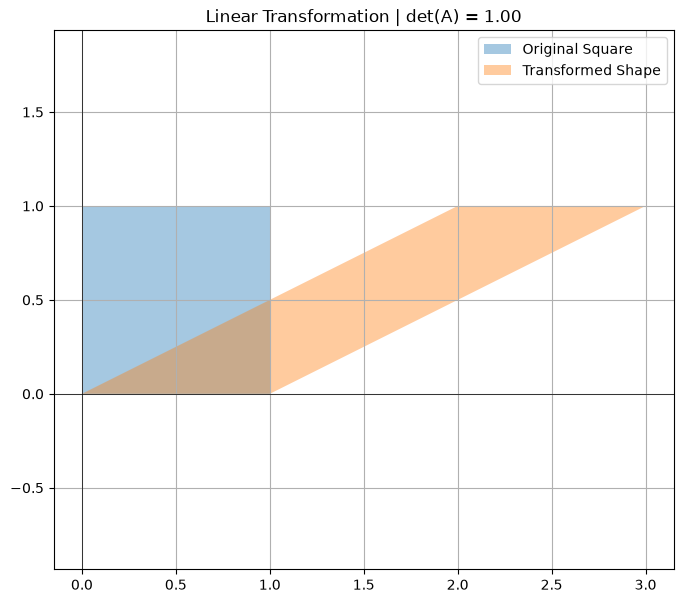

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Transformation Matrix
A = np.array([[1, 2], [0, 1]])

# Original Unit Square
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])

# Apply Linear Transformation
transformed = square @ A.T

# Calculate Determinant
det = np.linalg.det(A)

print("Determinant:", round(det, 6))
print("Area Scale Factor:", abs(det))

# Visualization
plt.figure(figsize=(8, 7))

plt.fill(square[:, 0], square[:, 1], alpha=0.4, label="Original Square")

plt.fill(transformed[:, 0], transformed[:, 1], alpha=0.4, label="Transformed Shape")

plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.title(f"Linear Transformation | det(A) = {det:.2f}")

plt.show()

In [37]:
import numpy as np

a = np.array([2, 1])
b = np.array([1, 3])

# Projection of b onto a
p = (a @ b / (a @ a)) * a

# Error vector
e = b - p

print("Projection:", p)
print("Error:", e)
print("Dot Product:", p @ e)

Projection: [2. 1.]
Error: [-1.  2.]
Dot Product: 0.0


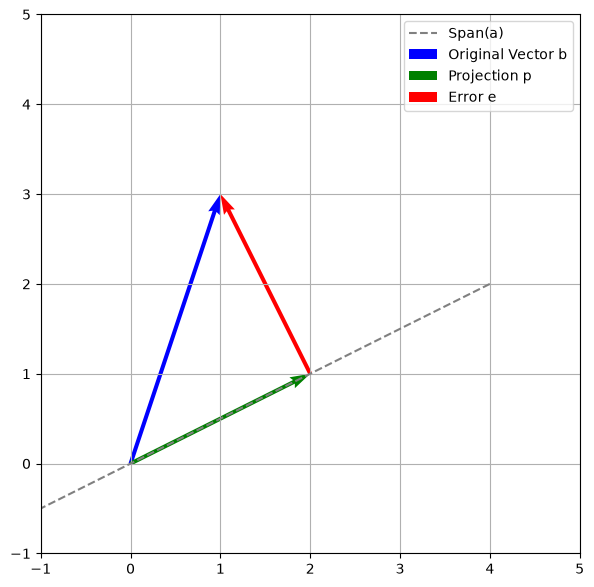

In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7))

# Line generated by a
t = np.linspace(-1, 2, 100)
line = t[:, None] * a

ax.plot(line[:, 0], line[:, 1], "--", color="gray", label="Span(a)")

# Original vector b
ax.quiver(
    0,
    0,
    *b,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue",
    label="Original Vector b"
)

# Projection vector p
ax.quiver(
    0,
    0,
    *p,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="green",
    label="Projection p"
)

# Error vector e: from p to b
ax.quiver(*p, *e, angles="xy", scale_units="xy", scale=1, color="red", label="Error e")

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.set_aspect("equal")

ax.grid(True)
ax.legend()
plt.show()

In [39]:
print("Length of b:", np.linalg.norm(b))
print("Length of p:", np.linalg.norm(p))
print("Length of e:", np.linalg.norm(e))

Length of b: 3.1622776601683795
Length of p: 2.23606797749979
Length of e: 2.23606797749979


In [40]:
import numpy as np

A = np.array([[1, 0], [1, 1], [1, 2]])

b = np.array([1, 2, 2])

# Least Squares solution
x_hat = np.linalg.lstsq(A, b, rcond=None)[0]

# Projection onto Column Space
p = A @ x_hat

# Error vector
e = b - p

print("x_hat:", x_hat)
print("Projection:", p)
print("Error:", e)

print("A.T @ e:", A.T @ e)
print("p @ e:", p @ e)

x_hat: [1.16666667 0.5       ]
Projection: [1.16666667 1.66666667 2.16666667]
Error: [-0.16666667  0.33333333 -0.16666667]
A.T @ e: [1.99840144e-15 1.77635684e-15]
p @ e: 3.2751579226442118e-15


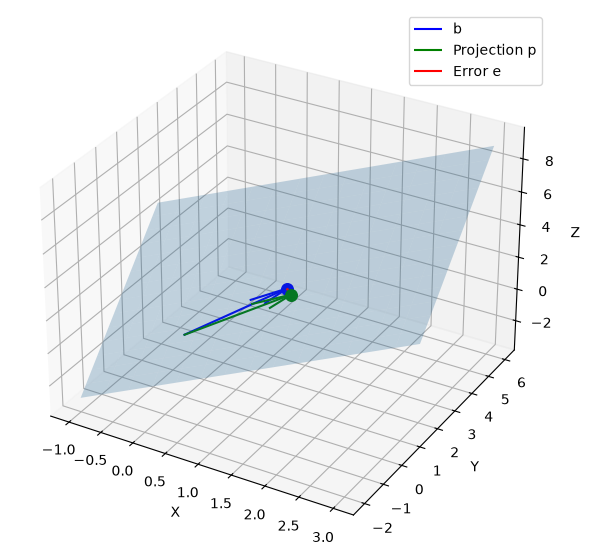

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# Least Squares
x_hat = np.linalg.lstsq(A, b, rcond=None)[0]

p = A @ x_hat
e = b - p

# Generate the Column Space plane
s, t = np.meshgrid(np.linspace(-1, 3, 15), np.linspace(-1, 3, 15))

plane = s[..., None] * A[:, 0] + t[..., None] * A[:, 1]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Column Space
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2], alpha=0.25)

# Original vector
ax.quiver(0, 0, 0, *b, color="blue", label="b")

# Projection
ax.quiver(0, 0, 0, *p, color="green", label="Projection p")

# Error: from p to b
ax.quiver(*p, *e, color="red", label="Error e")

ax.scatter(*p, color="green", s=70)
ax.scatter(*b, color="blue", s=70)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.legend()
plt.show()

In [42]:
print("Exact projection:", np.allclose(p, b))
print("Error magnitude:", np.linalg.norm(e))

Exact projection: False
Error magnitude: 0.4082482904638629


In [43]:
b = np.array([1, 1, 1])

x_hat = np.linalg.lstsq(A, b, rcond=None)[0]

p = A @ x_hat
e = b - p

print("x_hat:", x_hat)
print("Projection:", p)
print("Error:", e)

print("Exact projection:", np.allclose(p, b))
print("Error magnitude:", np.linalg.norm(e))

x_hat: [1.00000000e+00 6.40987562e-17]
Projection: [1. 1. 1.]
Error: [3.33066907e-16 2.22044605e-16 2.22044605e-16]
Exact projection: True
Error magnitude: 4.577566798522237e-16
